# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

Mohamed Hiba

**Week 4 dashboard link:** No original Week 04 dashboard was built. A new catch-up dashboard was created on October 14, 2026, after Parts 1 and 2 were recorded. Live catch-up dashboard: https://mohamedhiba-movielens.streamlit.app/ . Source and actual build log: https://github.com/mohamedhiba/movielens-dashboard .

**Scope disclosure:** This is a catch-up comparison, not a retrospective audit of a Week 04 artifact. No earlier build history or prompts are invented. Historical Week 04 evidence is unavailable; the actual catch-up prompts are documented below. The catch-up dashboard is publicly deployed on Streamlit Community Cloud. Parts 1 and 2 were completed with AI assistance at the student's request; they should not be represented as unaided work.

---


Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv", "Week-06-EDA-and-Dashboards/data/movie_ratings.csv"] if Path(p).exists())
# ZIP codes are identifiers; preserve leading zeros.
df = pd.read_csv(data_path, dtype={"zip_code": "string"})
display(df.head())


,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [2]:
print("Shape:", df.shape)
print("Users:", df.user_id.nunique(), "Movies:", df.movie_id.nunique())
display(df.dtypes.to_frame("dtype"))
display(df.isna().sum().to_frame("missing"))
print("Exact duplicates:", df.duplicated().sum())
print("Repeated user/movie pairs:", df.duplicated(["user_id", "movie_id"]).sum())
display(df.describe().T)
print("Missing-year movies:")
display(df.loc[df.year.isna(), ["movie_id", "title", "genres"]].drop_duplicates())
print("Unknown genre labels:")
display(df.loc[df.genres.eq("unknown"), ["movie_id", "title"]].drop_duplicates())
print("Rating date range:", pd.to_datetime(df.timestamp).min(), "to", pd.to_datetime(df.timestamp).max())
assert df.rating.between(1, 5).all()
# Check that a movie ID has consistent title/year/genres before deduplicating.
assert df.groupby("movie_id")[["title", "year", "genres"]].nunique(dropna=False).le(1).all().all()
movies = df[["movie_id", "title", "year", "genres"]].drop_duplicates("movie_id")
genre_movies = movies.assign(genre=movies.genres.str.split("|")).explode("genre")
genre_ratings = df.assign(genre=df.genres.str.split("|")).explode("genre")


Shape: (100000, 13)
Users: 943 Movies: 1682


,dtype
user_id,int64
movie_id,int64
rating,int64
timestamp,str
age,int64
gender,str
occupation,str
zip_code,string
title,str
year,float64


,missing
user_id,0
movie_id,0
rating,0
timestamp,0
age,0
gender,0
occupation,0
zip_code,0
title,0
year,30


Exact duplicates: 0
Repeated user/movie pairs: 0


,count,mean,std,min,25%,50%,75%,max
user_id,100000.0,462.484750,266.614420,1.0,254.0,447.0,682.0,943.0
movie_id,100000.0,425.530130,330.798356,1.0,175.0,322.0,631.0,1682.0
rating,100000.0,3.529860,1.125674,1.0,3.0,4.0,4.0,5.0
age,100000.0,32.969850,11.562623,7.0,24.0,30.0,40.0,73.0
year,99970.0,1987.748224,14.140014,1922.0,1986.0,1994.0,1996.0,1998.0
decade,99970.0,1982.780134,13.820687,1920.0,1980.0,1990.0,1990.0,1990.0
rating_year,100000.0,1997.471010,0.499161,1997.0,1997.0,1997.0,1998.0,1998.0


Missing-year movies:


,movie_id,title,genres
2172,267,unknown,unknown
6459,1128,Heidi Fleiss: Hollywood Madam (1995),Documentary
23637,1412,Land Before Time III: The Time of the Great Gi...,Animation|Children
69734,1635,Two Friends (1986),Drama
78008,1201,Marlene Dietrich: Shadow and Light (1996),Documentary


Unknown genre labels:


,movie_id,title
2172,267,unknown
8567,1373,Good Morning (1971)


Rating date range: 1997-09-20 03:05:10 to 1998-04-22 23:10:38


**✏️ Data notes:** There are 100,000 ratings, 943 users and 1,682 movie IDs, with no exact duplicate rows or repeated user/movie pairs; ratings are within 1–5, ages span 7–73, and known release years span 1922–1998. Release year and decade are missing for 30 ratings across five movies; I retain those ratings for genre/movie analyses and exclude them only from release-year charts, without guessing years from titles. Two movie IDs carry the `unknown` genre label (10 ratings); I show it as a missing-label category but exclude it from best/worst named-genre claims, and preserve ZIP codes as strings.


## 1.2 Decide before you chart

**Q1 Genre breakdown**
- My choice: Count distinct movie IDs per genre, with a multi-genre movie counted once in every applicable genre; divide each count by all 1,682 rated movies for percentages.
- Why: The question asks about movies, not rating activity; memberships overlap, so these percentages are not mutually exclusive market shares and do not sum to 100%.

**Q2 Genre satisfaction**
- My choice: Compute the mean of all individual ratings assigned to each genre after exploding, with rating counts and distinct movie counts beside it; keep all named genres, flag groups below 1,000 ratings, and display `unknown` separately.
- Why: This measures average recorded rating activity; well-rated popular movies receive more weight, and counts reveal where evidence is sparse. A multi-genre rating contributes to several categories, so genre means are not independent.

**Q3 Ratings over time**
- My choice: Group by movie release year, average individual ratings, and plot annual rating counts in a separate aligned panel; omit only missing release years and flag years with fewer than 100 ratings.
- Why: The question specifies release year, which differs from when a rating was recorded; unequal sample sizes make some yearly averages less stable. I do not interpolate years with no data.

**Q4 Best movies**
- My choice: Average individual ratings per movie ID, then use counts ≥50 or ≥150; sort by mean descending, count descending, title ascending, and movie ID ascending for a reproducible tie-break.
- Why: “At least” includes the boundary, IDs avoid combining different movies with similar titles, and computing counts before selecting the top five keeps the sample floor meaningful.

These choices were committed before inspecting any dashboard.


---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

,movies,pct_of_rated_movies
genre,,
Drama,725,43.10
Comedy,505,30.02
Action,251,14.92
Thriller,251,14.92
Romance,247,14.68
Adventure,135,8.03
Children,122,7.25
Crime,109,6.48
Sci-Fi,101,6.00


Total genre memberships: 2893


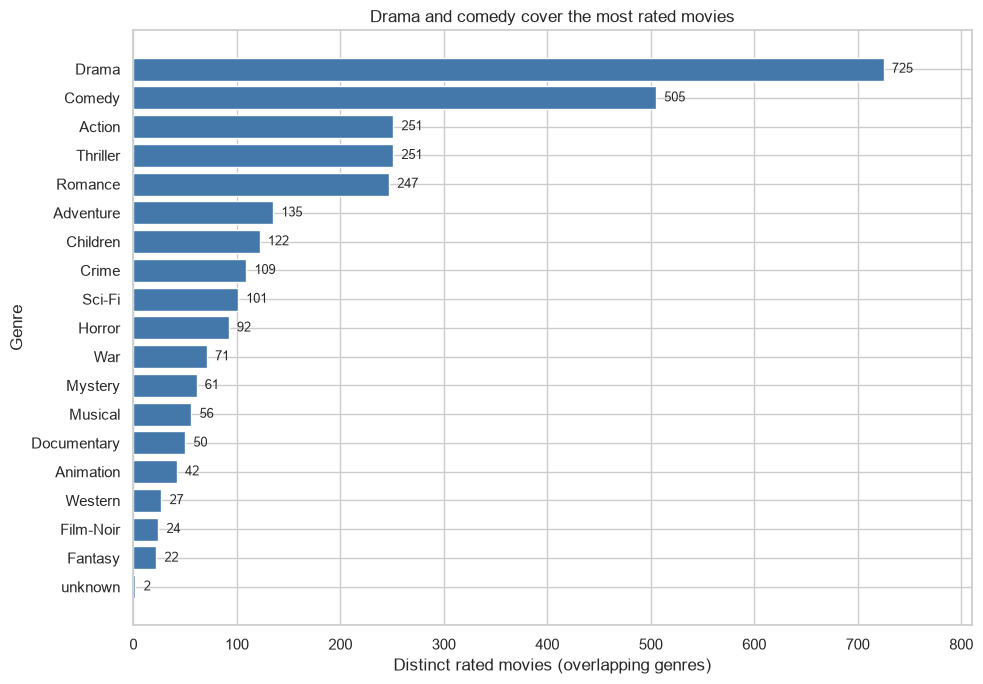

In [3]:
genre_counts = genre_movies.groupby("genre").movie_id.nunique().sort_values(ascending=False).to_frame("movies")
genre_counts["pct_of_rated_movies"] = 100 * genre_counts.movies / len(movies)
display(genre_counts.round(2))
print("Total genre memberships:", genre_counts.movies.sum())
fig, ax = plt.subplots(figsize=(10, 7))
ordered = genre_counts.sort_values("movies")
ax.barh(ordered.index, ordered.movies, color="#4477AA")
for i, value in enumerate(ordered.movies):
    ax.text(value + 8, i, str(value), va="center", fontsize=9)
ax.set(xlabel="Distinct rated movies (overlapping genres)", ylabel="Genre", title="Drama and comedy cover the most rated movies", xlim=(0, 810))
fig.tight_layout()
plt.show()


**✏️ My answer (with numbers):** Drama appears in 725 of 1,682 rated movies (43.10%) and Comedy in 505 (30.02%), a difference of 220 movies or 13.08 percentage points. Action and Thriller tie at 251 movies each (14.92%), followed by Romance at 247 (14.68%). I count movie IDs once per applicable genre, producing 2,893 memberships; overlapping genres mean the percentages sum to more than 100%, not a partition of the audience or revenue.


## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

,mean_rating,ratings,movies,std,sparse_flag
genre,,,,,
Film-Noir,3.9215,1733,24,0.9934,False
War,3.8158,9398,71,1.0803,False
Drama,3.6874,39895,725,1.0791,False
Documentary,3.6728,758,50,1.1805,True
Mystery,3.6381,5245,61,1.0911,False
Crime,3.6323,8055,109,1.1125,False
Romance,3.6217,19461,247,1.0961,False
Western,3.6133,1854,27,1.0419,False
Animation,3.5767,3605,42,1.0966,False


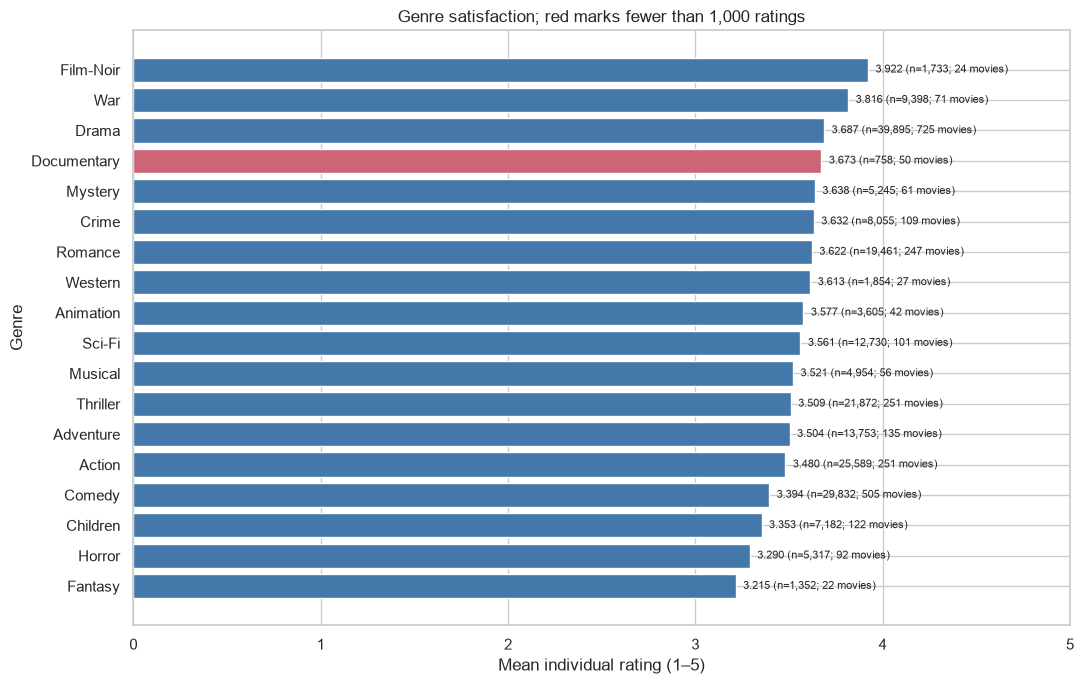

In [4]:
genre_summary = genre_ratings.groupby("genre").agg(
    mean_rating=("rating", "mean"), ratings=("rating", "size"),
    movies=("movie_id", "nunique"), std=("rating", "std"))
genre_summary["sparse_flag"] = genre_summary.ratings.lt(1000)
genre_summary = genre_summary.sort_values("mean_rating", ascending=False)
display(genre_summary.round(4))
named_genres = genre_summary.drop(index="unknown")
ordered = named_genres.sort_values("mean_rating")
fig, ax = plt.subplots(figsize=(11, 7))
colors = ["#CC6677" if value else "#4477AA" for value in ordered.sparse_flag]
ax.barh(ordered.index, ordered.mean_rating, color=colors)
for i, row in enumerate(ordered.itertuples()):
    ax.text(row.mean_rating + .04, i, f"{row.mean_rating:.3f} (n={row.ratings:,}; {row.movies} movies)", va="center", fontsize=8)
ax.set(xlabel="Mean individual rating (1–5)", ylabel="Genre", title="Genre satisfaction; red marks fewer than 1,000 ratings", xlim=(0, 5))
fig.tight_layout()
plt.show()


**✏️ My answer (with numbers):** Film-Noir has the highest named-genre average, 3.922 from 1,733 ratings of 24 movies, followed by War at 3.816 from 9,398 ratings of 71 movies. Fantasy is lowest at 3.215 from 1,352 ratings of 22 movies, followed by Horror at 3.290 from 5,317 ratings of 92 movies. The `unknown` label averages 3.200 but has only 10 ratings of two movies, so I do not call it a real worst genre; Documentary also warrants caution (3.673 from 758 ratings of 50 movies).


## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

,mean_rating,ratings,movies
year,,,
1922,3.5556,54,1
1926,3.0000,2,1
1930,3.7778,18,1
1931,4.0000,44,1
1932,3.8333,12,1
...,...,...,...
1994,3.4201,9034,237
1995,3.4146,12389,294
1996,3.3111,18744,297


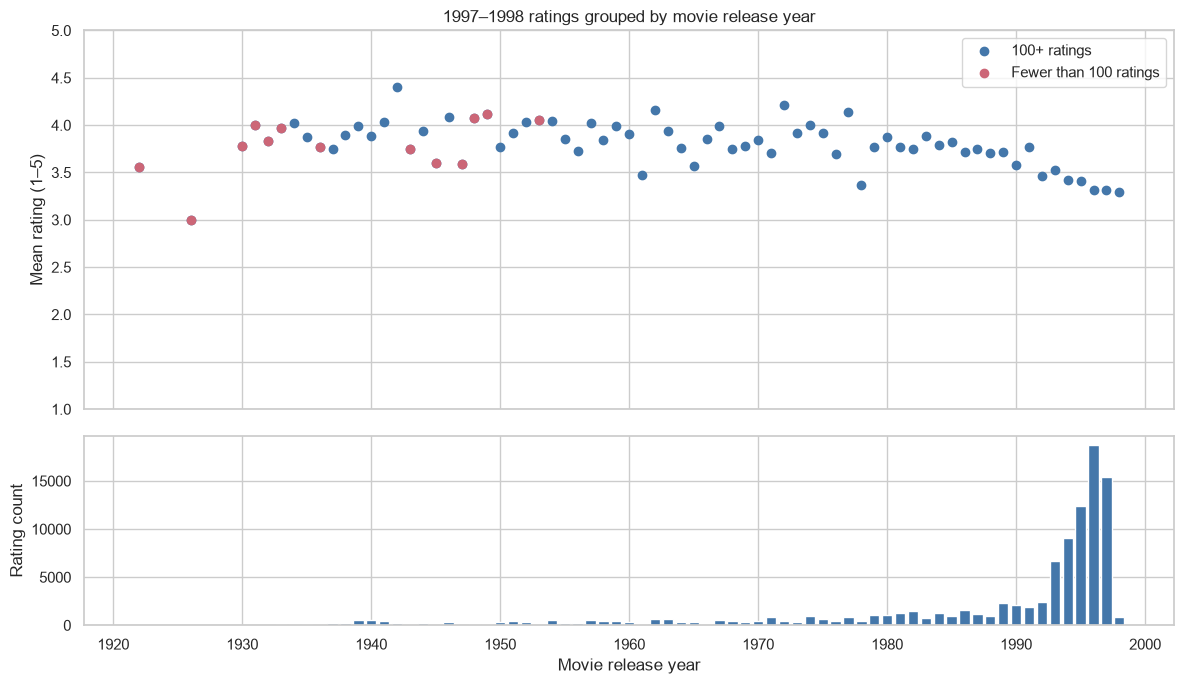

In [5]:
year_summary = df.dropna(subset=["year"]).groupby("year").agg(
    mean_rating=("rating", "mean"), ratings=("rating", "size"), movies=("movie_id", "nunique"))
year_summary.index = year_summary.index.astype(int)
display(year_summary.round(4))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].scatter(year_summary.index, year_summary.mean_rating, color="#4477AA", label="100+ ratings")
sparse_years = year_summary.loc[year_summary.ratings.lt(100)]
axes[0].scatter(sparse_years.index, sparse_years.mean_rating, color="#CC6677", label="Fewer than 100 ratings")
axes[0].set(ylabel="Mean rating (1–5)", ylim=(1, 5), title="1997–1998 ratings grouped by movie release year")
axes[0].legend()
axes[1].bar(year_summary.index, year_summary.ratings, color="#4477AA")
axes[1].set(xlabel="Movie release year", ylabel="Rating count")
fig.tight_layout()
plt.show()


**✏️ My answer (with numbers):** Older represented releases often average around 3.8–4.1, while 1994–1998 releases average roughly 3.30–3.42; for example, 1942 averages 4.398 from 261 ratings of two movies, versus 1996's 3.311 from 18,744 ratings of 297 movies. Evidence is very uneven: 1926 has just two ratings of one film (mean 3.000), while 1995 has 12,389 ratings of 294 films (mean 3.415). The chart describes how 1997–1998 users rated movies from different release years, not a historical change in viewers' tastes or proof that older movies are intrinsically better; 30 missing-year ratings are excluded.


## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

At least 50 ratings; eligible movies: 603


,movie_id,title,mean_rating,ratings
407,408,"Close Shave, A (1995)",4.491071,112
317,318,Schindler's List (1993),4.466443,298
168,169,"Wrong Trousers, The (1993)",4.466102,118
482,483,Casablanca (1942),4.456790,243
113,114,Wallace & Gromit: The Best of Aardman Animatio...,4.447761,67


At least 150 ratings; eligible movies: 203


,movie_id,title,mean_rating,ratings
317,318,Schindler's List (1993),4.466443,298
482,483,Casablanca (1942),4.456790,243
63,64,"Shawshank Redemption, The (1994)",4.445230,283
602,603,Rear Window (1954),4.387560,209
11,12,"Usual Suspects, The (1995)",4.385768,267


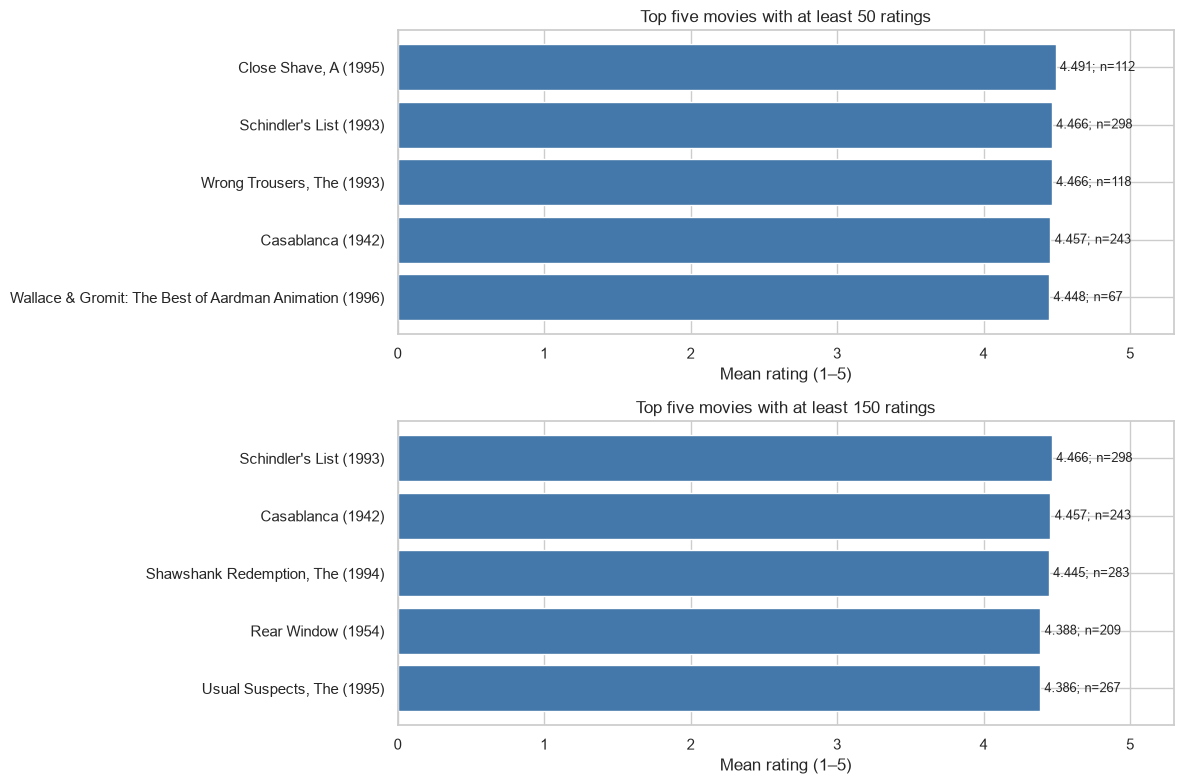

In [6]:
movie_summary = df.groupby(["movie_id", "title"]).agg(
    mean_rating=("rating", "mean"), ratings=("rating", "size")).reset_index()
movie_summary = movie_summary.sort_values(
    ["mean_rating", "ratings", "title", "movie_id"], ascending=[False, False, True, True])
top50 = movie_summary.loc[movie_summary.ratings.ge(50)].head(5)
top150 = movie_summary.loc[movie_summary.ratings.ge(150)].head(5)
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, floor, top in zip(axes, [50, 150], [top50, top150]):
    print(f"At least {floor} ratings; eligible movies: {movie_summary.ratings.ge(floor).sum()}")
    display(top.round(6))
    ordered = top.iloc[::-1]
    ax.barh(ordered.title, ordered.mean_rating, color="#4477AA")
    for i, row in enumerate(ordered.itertuples()):
        ax.text(row.mean_rating + .03, i, f"{row.mean_rating:.3f}; n={row.ratings}", va="center", fontsize=9)
    ax.set(xlabel="Mean rating (1–5)", xlim=(0, 5.3), title=f"Top five movies with at least {floor} ratings")
fig.tight_layout()
plt.show()


**✏️ My answer (with numbers):** With ≥50 ratings (603 eligible movies), the top five are *A Close Shave* (4.4911, n=112), *Schindler's List* (4.4664, n=298), *The Wrong Trousers* (4.4661, n=118), *Casablanca* (4.4568, n=243), and *Wallace & Gromit: The Best of Aardman Animation* (4.4478, n=67). With ≥150 ratings (203 eligible movies), the list becomes *Schindler's List* (4.4664, n=298), *Casablanca* (4.4568, n=243), *The Shawshank Redemption* (4.4452, n=283), *Rear Window* (4.3876, n=209), and *The Usual Suspects* (4.3858, n=267). The three animation titles lose eligibility, letting the last three films enter; a higher floor reduces exposure to unstable small samples but does not prove that excluded films are worse or correct selection bias.


> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

# Part 3: Analysis

## 3.1 How the dashboard got built

There was no original Week 04 dashboard or historical build log. These are two **actual catch-up conversation prompts**, recorded on October 14, 2026; the first requests the homework as a whole and the second delegates the dashboard design. They are not fabricated Week 04 design prompts.

**Prompt 1**
- What I asked: “ok i week passed, now lets do HW for week 6 do ahead and do it”
- AI's first attempt: After the missing Week 04 dashboard was disclosed (“i didn't do that thing”), AI recorded the independent notebook analysis, then built a Streamlit dashboard with four sections: overlapping movie-genre counts, rating-level genre averages, release-year means/counts, and inclusive 50/150 top-five lists. It also added a genre selector and custom-floor slider.
- What I changed (or accepted without checking): I supplied no detailed design requirements before this first version; AI chose the methodology and presentation. Automated checks and browser inspection subsequently verified the calculations and controls, rather than assuming that generated code was correct.

**Prompt 2**
- What I asked: “you do it idk” in response to the request for dashboard content and a design/feature requirement.
- AI's first attempt: AI retained the already prepared dashboard's design and recorded my delegation in the catch-up build log, rather than inventing earlier prompts or introducing unnecessary visual changes.
- What I changed (or accepted without checking): I delegated the design and did not request a revision. The tested dashboard was accepted as the current baseline; this was not a manual review by me of every analytical choice.

**Verification and scope:** Streamlit's application test verified both controls, the browser displayed all four sections, and independent aggregate checks matched the notebook definitions. Source and build log: https://github.com/mohamedhiba/movielens-dashboard . The comparison below is limited to this new artifact and cannot establish what an unbuilt Week 04 dashboard would have said.


## 3.2 Compare the answers

The dashboard below is the **new October 14 catch-up dashboard**, using all genres and the full dataset. Agreement does not establish what an unbuilt Week 04 dashboard would have said.

**Q1**
- Dashboard says: Drama 725 (43.1034%), Comedy 505 (30.0238%), Action and Thriller 251 each; 1,682 distinct rated movies.
- I say: The same counts and percentages; 2,893 overlapping memberships overall.
- Same? Yes, at the default all-genre setting.
- If different, why? No numerical difference: both deduplicate movie IDs before splitting the genre strings. The dashboard exposes percentages on hover and in a table.

**Q2**
- Dashboard says: Film-Noir 3.9215 (1,733 ratings, 24 films); Fantasy 3.2152 (1,352 ratings, 22 films); `unknown` 3.2000 (10 ratings, two films).
- I say: Film-Noir is the best and Fantasy the worst named genre; `unknown` is not a genre and its sample is tiny.
- Same? Partly: numerical summaries match, but my chart excludes `unknown` from the ranking of named genres.
- If different, why? The app's `summarize` groups all exploded labels, including `unknown`; the notebook's `named_genres = genre_summary.drop(index="unknown")` excludes that missing-label category from best/worst genre claims. The dashboard warns about its meaning in the caption.

**Q3**
- Dashboard says: 1942 4.3985 (261 ratings), 1996 3.3111 (18,744 ratings); 30 missing-year ratings omitted.
- I say: The same annual means/counts, with sparse years highlighted.
- Same? Yes numerically; chart presentation differs.
- If different, why? Both group by the release-year field after dropping missing year. The dashboard connects observed years with a line, whereas my scatter chart avoids suggesting measurements between sparse observations.

**Q4**
- Dashboard says: At ≥50, A Close Shave, Schindler's List, The Wrong Trousers, Casablanca, Wallace & Gromit: The Best of Aardman Animation; at ≥150, Schindler's List, Casablanca, The Shawshank Redemption, Rear Window, The Usual Suspects.
- I say: The same lists, means, counts and eligibility totals (603 and 203 movies).
- Same? Yes.
- If different, why? Both compute movie-ID means and counts first, use `.ge(floor)`, then sort on mean/count/title/ID; the app's custom slider does not change its two required fixed-floor lists.

**✏️ Q1 explanation:** Inspecting the dashboard source shows it makes one row per movie ID before splitting pipe-separated genres, then calls `groupby("genre").movie_id.nunique()`. That is why the Drama count is 725 rather than the 39,895 Drama rating records; deduplication changes the unit being counted, and the overlap warning prevents interpreting these as disjoint shares.

**✏️ Q2 explanation:** The source averages `rating` directly on the exploded rating table; it does not average movie means first. Recomputing with equal movie weights lowers Film-Noir from 3.9215 to 3.5484 and Drama from 3.6874 to 3.1874; the top genre stays the same, but the numbers and other rankings change because popular movies receive more weight in the rating-level mean.


## 3.3 Chart choices

**Q1**
- Chart the catch-up dashboard used: Sorted horizontal bars, with movie percentages in hover and a table.
- Chart I used: Sorted horizontal bars with printed movie counts.
- Which communicates better, and why? Both support category comparison and start counts at zero; my static labels are quicker to read without hovering, while the dashboard supports filtering. A pie chart would wrongly suggest mutually exclusive slices.

**Q2**
- Chart the catch-up dashboard used: Sorted horizontal bars with hover counts, a 0–5 axis, and sparse groups colored differently; `unknown` remains visible.
- Chart I used: Sorted horizontal bars with mean, rating count and movie count printed next to every named genre, also on a 0–5 axis.
- Which communicates better, and why? The notebook puts evidence beside each average without requiring hover and separates missing metadata from named genres; the dashboard's long genre labels remain readable and its sparse-group color is useful.

**Q3**
- Chart the catch-up dashboard used: A line with markers, a 1–5 rating axis, and a second rating-count bar chart.
- Chart I used: A release-year scatter chart with years below 100 ratings marked red, above an aligned count panel.
- Which communicates better, and why? The notebook explicitly marks thin samples and avoids lines bridging unobserved years; both identify the x-axis as movie release year and show unequal evidence. Neither supports a claim about tastes changing through the decades.

**Q4**
- Chart the catch-up dashboard used: Two sorted horizontal bar charts, tables with exact counts, and a custom-floor slider; rating axes begin at zero and extend to five.
- Chart I used: Two horizontal bar charts with means and counts printed beside long movie titles, and tables.
- Which communicates better, and why? The notebook provides a compact comparison with counts on-chart; the dashboard allows more threshold exploration. Starting bars at zero avoids overstating the very small mean differences, so exact values and rank order matter more than apparent bar length.


In [7]:
user_counts = df.groupby("user_id").size()
print("Fewest and most ratings per user:", user_counts.min(), user_counts.max())
print("Distinct rating years:", sorted(df.rating_year.unique()))
display(df.rating_year.value_counts().sort_index().to_frame("ratings"))
print("Distinct users by gender:")
display(df[["user_id", "gender"]].drop_duplicates().gender.value_counts())
bottom_genre = named_genres.mean_rating.idxmin()
bottom = genre_ratings.loc[genre_ratings.genre.eq(bottom_genre), "rating"]
rough_ci = (bottom.mean() - 1.96 * bottom.std(ddof=1) / np.sqrt(len(bottom)),
            bottom.mean() + 1.96 * bottom.std(ddof=1) / np.sqrt(len(bottom)))
print(f"Bottom named genre: {bottom_genre}, mean={bottom.mean():.6f}, n={len(bottom)}, movies={named_genres.loc[bottom_genre, 'movies']}")
print("Rough rating-level 95% interval:", rough_ci)
movie_means = df.groupby("movie_id").rating.mean()
equal_movie_means = genre_movies.assign(movie_mean=genre_movies.movie_id.map(movie_means)).groupby("genre").movie_mean.mean()
average_comparison = genre_summary[["mean_rating", "ratings", "movies"]].join(equal_movie_means.rename("equal_movie_mean"))
display(average_comparison.round(4))
print("Top named genre with equal movie weights:", equal_movie_means.drop("unknown").idxmax())


Fewest and most ratings per user: 20 737
Distinct rating years: [np.int64(1997), np.int64(1998)]


,ratings
rating_year,
1997,52899
1998,47101


Distinct users by gender:


gender
M    670
F    273
Name: count, dtype: int64

Bottom named genre: Fantasy, mean=3.215237, n=1352, movies=22
Rough rating-level 95% interval: (np.float64(3.1555761418721917), np.float64(3.274897230908873))


,mean_rating,ratings,movies,equal_movie_mean
genre,,,,
Film-Noir,3.9215,1733,24,3.5484
War,3.8158,9398,71,3.4892
Drama,3.6874,39895,725,3.1874
Documentary,3.6728,758,50,3.2293
Mystery,3.6381,5245,61,3.3368
Crime,3.6323,8055,109,3.2110
Romance,3.6217,19461,247,3.2440
Western,3.6133,1854,27,3.1856
Animation,3.5767,3605,42,3.2988


Top named genre with equal movie weights: Film-Noir


## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:**

**1. Who is in the data?** Each of the 943 users contributes between 20 and 737 ratings, and all ratings were recorded in 1997 (52,899) or 1998 (47,101). There are 670 male and 273 female users, so this is a self-selected, historically specific group of active MovieLens raters, not a representative sample of today's viewers; people with few/no ratings are missing, and heavy raters have more influence on Q2.

**2. How sure am I about the bottom genre?** Fantasy is the lowest named genre (3.2152), based on 1,352 ratings of 22 movies; the requested rough interval is 3.1556–3.2749. I would not bet that it is universally the worst: the formula treats ratings as independent even though users repeat and movies cluster, genres overlap, and the dataset contains only a small selected set of fantasy films; the interval omits these uncertainties.

**3. What can Q3 say about time?** `rating_year` has only two values, 1997 and 1998, so a chart grouped by release year cannot show changes in public taste from 1922 onward. It compares release cohorts as rated during one short observation period; the high 1942 mean (4.3985 from two films) may reflect classics surviving into the catalog and enthusiasts choosing to rate them, rather than all 1942 releases being superior.

**4. Does averaging matter?** Film-Noir remains the top genre, but its mean falls from 3.9215 (all ratings weighted equally) to 3.5484 (each of 24 movie means weighted equally). Drama changes from 3.6874 to 3.1874, while Musical rises from 11th to 3rd among named genres; these summaries answer different questions, and agreement on the top genre does not make the weighting choice irrelevant. This is evidence of weighting/selection differences, not by itself proof of Simpson's paradox.

**5. Deployment risk.** A studio could interpret Film-Noir's 3.9215 as evidence that funding any new Film-Noir title will produce higher satisfaction or revenue. My caveat would be: “Ratings describe selected movies and active MovieLens users in 1997–1998; genre averages do not predict revenue or establish a causal benefit of making a film in that genre.”


## 3.5 Verdict

**Where I'd override the AI:** The catch-up dashboard keeps `unknown` in the genre-average chart; I would show it in a separate metadata panel so users do not mistake ten ratings with missing labels for evidence about a real genre. I would also replace the release-year line with sparse-sample-marked points, as in my notebook, to avoid implying a continuous well-measured trend.

**Where the AI held up:** The generated app correctly deduplicates movies before counting genre coverage, separates release year from rating year, and applies the 50/150 floors inclusively before ranking. Its default numerical results agree with the independently recorded notebook calculations, and both controls passed application checks.

**One sentence:** There was no Week 04 dashboard to judge; in this catch-up workflow the student requested the homework and disclosed that gap, while AI chose and implemented the current analysis/dashboard, so this cannot be presented as a student-driven historical build.


---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [x] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [x] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [x] Every ✏️ cell and every fill-in line is filled in
- [x] Open a PR from your fork, same as every other week